In [1]:
# Cell 1 — verify environment
import seaborn as sns
import pandas as pd
import matplotlib
import sklearn

print("seaborn   :", sns.__version__)
print("pandas    :", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("sklearn   :", sklearn.__version__)

df = sns.load_dataset('iris')
print("\nDataset loaded! Shape:", df.shape)
df.head()

seaborn   : 0.13.2
pandas    : 3.0.2
matplotlib: 3.10.9
sklearn   : 1.8.0

Dataset loaded! Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
# Cell 2 — Basic exploration
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nSpecies count:\n", df['species'].value_counts())
print("\nStatistics:\n", df.describe().round(2))

Shape: (150, 5)

Missing values:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species count:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Statistics:
        sepal_length  sepal_width  petal_length  petal_width
count        150.00       150.00        150.00       150.00
mean           5.84         3.06          3.76         1.20
std            0.83         0.44          1.77         0.76
min            4.30         2.00          1.00         0.10
25%            5.10         2.80          1.60         0.30
50%            5.80         3.00          4.35         1.30
75%            6.40         3.30          5.10         1.80
max            7.90         4.40          6.90         2.50


In [3]:
# Cell 3 — Visualizations setup
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

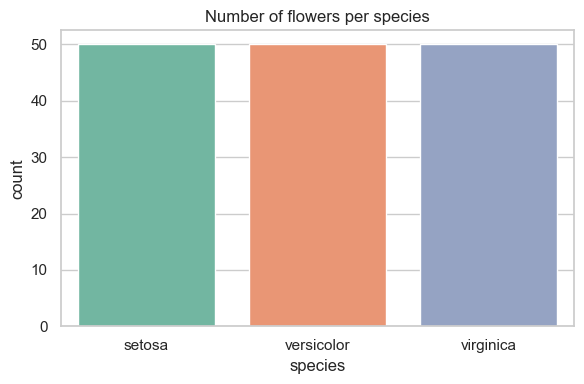

In [4]:
# Cell 4 — Count plot
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='species', hue='species', palette='Set2', legend=False)
plt.title('Number of flowers per species')
plt.tight_layout()
plt.show()

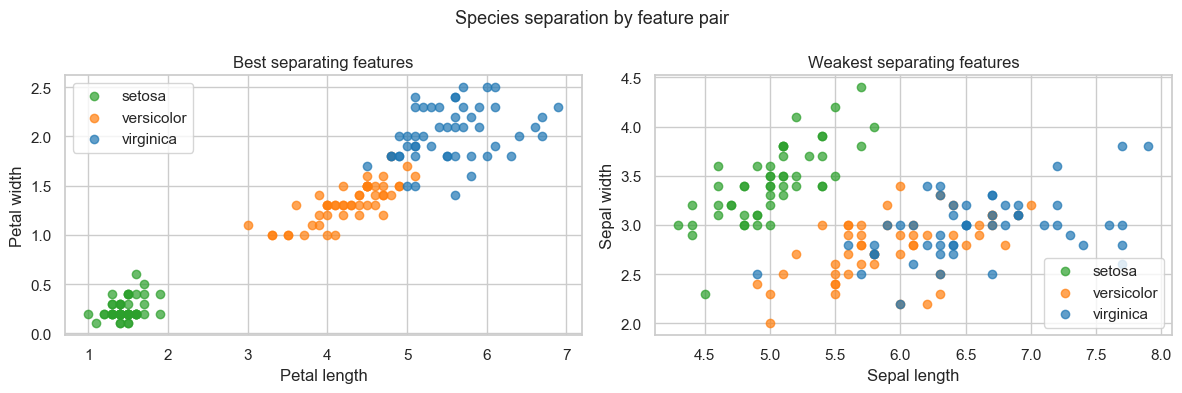

In [5]:
# Cell 6 — Scatter plot (replaces pairplot)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for species, color in zip(['setosa', 'versicolor', 'virginica'],
                           ['#2ca02c', '#ff7f0e', '#1f77b4']):
    subset = df[df['species'] == species]
    axes[0].scatter(subset['petal_length'], subset['petal_width'],
                    label=species, color=color, alpha=0.7)
    axes[1].scatter(subset['sepal_length'], subset['sepal_width'],
                    label=species, color=color, alpha=0.7)
axes[0].set(xlabel='Petal length', ylabel='Petal width', title='Best separating features')
axes[1].set(xlabel='Sepal length', ylabel='Sepal width', title='Weakest separating features')
axes[0].legend(); axes[1].legend()
plt.suptitle('Species separation by feature pair', fontsize=13)
plt.tight_layout()
plt.show()

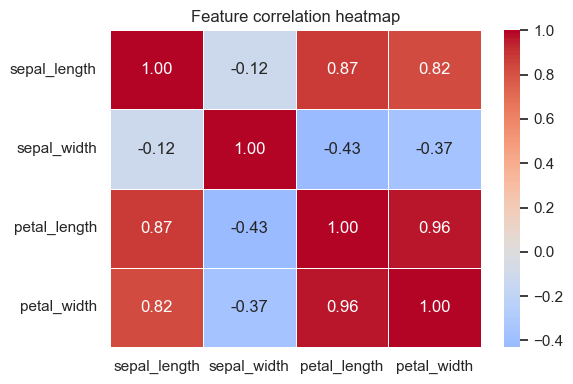

In [6]:
# Cell 7 — Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(df.drop(columns='species').corr(), annot=True, fmt=".2f",
            cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Feature correlation heatmap')
plt.tight_layout()
plt.show()

In [7]:
# Cell 8 — Feature and target separation
X = df.drop(columns='species')
y = df['species']
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", y.unique())

X shape: (150, 4)
y shape: (150,)
Classes: <StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str


In [8]:
# Cell 9 — Label encoding
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print("Before:", y[:5].values)
print("After: ", y_encoded[:5])
print("Mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

Before: <StringArray>
['setosa', 'setosa', 'setosa', 'setosa', 'setosa']
Length: 5, dtype: str
After:  [0 0 0 0 0]
Mapping: {'setosa': np.int64(0), 'versicolor': np.int64(1), 'virginica': np.int64(2)}


In [9]:
# Cell 10 — Train/test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)
print("Training set:", X_train.shape)
print("Test set:    ", X_test.shape)

Training set: (120, 4)
Test set:     (30, 4)


In [10]:
# Cell 11 — Train the Decision Tree
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

print("✅ Model trained!")
print("Number of nodes in tree:", model.tree_.node_count)
print("Tree depth:", model.get_depth())

✅ Model trained!
Number of nodes in tree: 9
Tree depth: 3


In [11]:
# Cell 12 — Predictions and accuracy
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"✅ Model Accuracy: {accuracy * 100:.1f}%")
print("\n--- Detailed Report ---")
print(classification_report(y_test, y_pred,
      target_names=le.classes_))

✅ Model Accuracy: 96.7%

--- Detailed Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



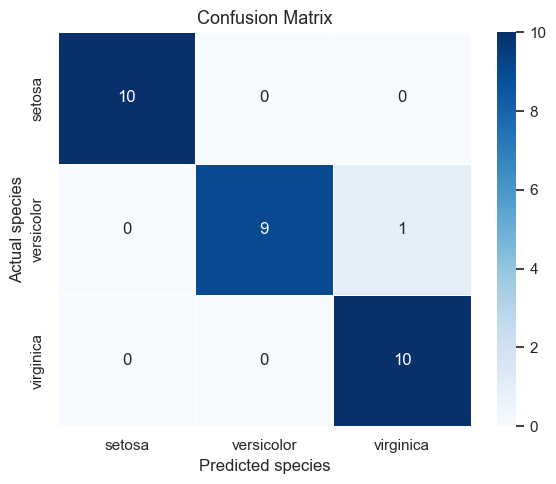

In [12]:
# Cell 13 — Confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_,
            linewidths=0.5)
plt.title('Confusion Matrix', fontsize=13)
plt.xlabel('Predicted species')
plt.ylabel('Actual species')
plt.tight_layout()
plt.show()

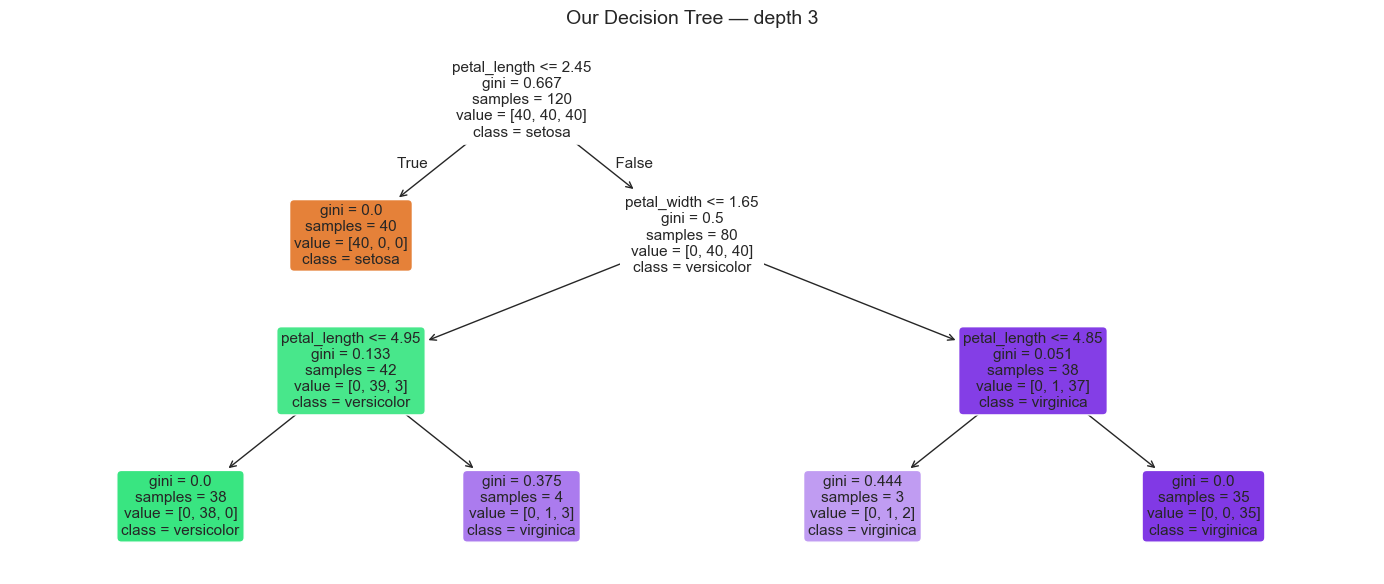

In [13]:
# Cell 14 — Visualise the Decision Tree
from sklearn.tree import plot_tree

plt.figure(figsize=(14, 6))
plot_tree(model,
          feature_names=X.columns.tolist(),
          class_names=le.classes_.tolist(),
          filled=True,
          rounded=True,
          fontsize=11)
plt.title('Our Decision Tree — depth 3', fontsize=14)
plt.tight_layout()
plt.show()

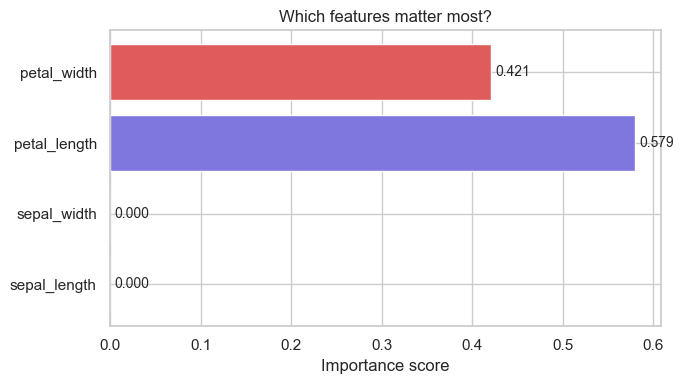

In [14]:
# Cell 15 — Feature importance
importances = model.feature_importances_
features = X.columns.tolist()

plt.figure(figsize=(7, 4))
bars = plt.barh(features, importances, color=['#4ec9b0','#ff9f40','#7f77dd','#e05c5c'])
plt.xlabel('Importance score')
plt.title('Which features matter most?')
for bar, val in zip(bars, importances):
    plt.text(val + 0.005, bar.get_y() + bar.get_height()/2,
             f'{val:.3f}', va='center', fontsize=10)
plt.tight_layout()
plt.show()